# Vòng 1 — Kiểm tra dữ liệu & đối soát dòng tiền két

**Mục tiêu**
1. Kiểm tra chất lượng 2 file gốc trước khi tạo bất kỳ feature nào.
2. Đối soát hóa đơn chi tiết với số chốt ca của máy POS.
3. Xây dựng đúng chỉ số **dòng tiền két không giải thích được** cho từng ca.

**Vì sao làm lại so với bản đã nộp (v1)?** Bản v1 dùng `Cash_Diff = tiền két thực − tiền mặt máy ghi trong ca`. Nhưng `actual_cash_in_drawer` là **tổng tiền đếm trong két** (gồm tiền tồn từ ca trước), và chủ quán có **rút tiền khỏi két mà không ghi lại**. Vì vậy `Cash_Diff` của v1 chủ yếu đo *tiền tồn két*, không đo sai lệch. Bản này dựng lại chỉ số từ phương trình cân bằng két:

$$\text{két}_t = \text{két}_{t-1} + \text{tiền mặt bán}_t - \text{tiền rút}_t + \varepsilon_t$$

Do **không có sổ ghi tiền rút**, ta chỉ quan sát được phần gộp $\text{gap}_t = \text{két}_t - (\text{két}_{t-1} + \text{tiền mặt bán}_t) = \varepsilon_t - \text{tiền rút}_t$.

**Input:** `data/raw/MainLog.csv`, `data/raw/DetailsTransaction.csv`
**Output:** `data/processed_v2/shifts_v2.csv`, `data/processed_v2/bills_v2.csv`

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# Notebook nằm trong Final-Project/notebook-v2/ -> dữ liệu ở Final-Project/data/
ROOT = Path.cwd().resolve().parent
RAW = ROOT / 'data' / 'raw'
PROC = ROOT / 'data' / 'processed_v2'      # CSV trung gian (gitignored, có dữ liệu kinh doanh)
OUT = Path.cwd() / 'outputs'                # hình + báo cáo tổng hợp đã ẩn danh
PROC.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

SEED = 42
TOL = 10_000   # tiền két được đếm tròn tới 10.000 đ -> sai số đếm ±10.000 đ

def vnd(x):
    return f"{x:,.0f} đ".replace(',', '.')

## 1. Đọc dữ liệu

In [2]:
main = pd.read_csv(RAW / 'MainLog.csv')
det = pd.read_csv(RAW / 'DetailsTransaction.csv')
main['timestamp'] = pd.to_datetime(main['timestamp'], format='%m/%d/%Y %H:%M:%S')
det['transaction_at'] = pd.to_datetime(det['transaction_at'], format='%m/%d/%Y %H:%M:%S')
main = main.sort_values('timestamp').reset_index(drop=True)
det = det.sort_values('transaction_at').reset_index(drop=True)

print(f"MainLog           : {main.shape[0]} dòng × {main.shape[1]} cột | {main.timestamp.min():%d/%m/%Y} → {main.timestamp.max():%d/%m/%Y}")
print(f"DetailsTransaction: {det.shape[0]} dòng × {det.shape[1]} cột | {det.transaction_at.min():%d/%m/%Y} → {det.transaction_at.max():%d/%m/%Y}")
display(main.head(3))
display(det.drop(columns='notes').head(3))

MainLog           : 242 dòng × 6 cột | 20/12/2025 → 30/04/2026
DetailsTransaction: 5412 dòng × 5 cột | 20/12/2025 → 30/04/2026


,timestamp,total_revenue,transfer_amount,cash_amount,is_morning_shift,actual_cash_in_drawer
0,2025-12-20 07:04:51,0,0,0,True,1240000
1,2025-12-20 11:53:49,867000,332000,535000,True,850000
2,2025-12-20 17:54:52,462000,250000,212000,False,860


,transaction_at,total_revenue,transfer_payment,cash_payment
0,2025-12-20 07:05:54,19000,0,19000
1,2025-12-20 07:42:26,19000,0,19000
2,2025-12-20 07:51:58,38000,0,38000


## 2. Kiểm tra hóa đơn chi tiết

,Số hóa đơn
Dòng trùng lặp hoàn toàn,0
Tổng tiền <= 0,0
Tiền mặt + chuyển khoản ≠ tổng tiền,1
Vừa tiền mặt vừa chuyển khoản,0
Có ghi chú (notes),101


,transaction_at,total_revenue,transfer_payment,cash_payment
1400,2026-01-21 13:07:01,122000,114000,0


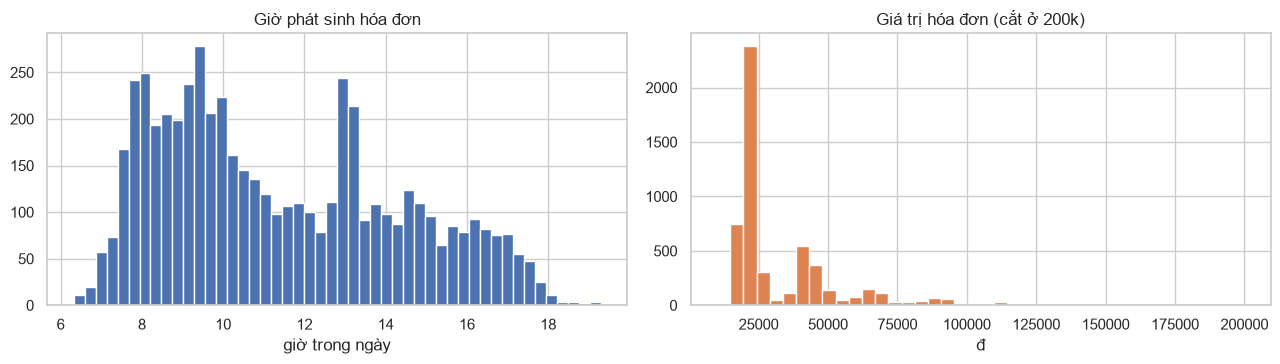

In [3]:
pay_sum_err = det.cash_payment + det.transfer_payment != det.total_revenue
checks = pd.Series({
    'Dòng trùng lặp hoàn toàn': det.duplicated().sum(),
    'Tổng tiền <= 0': (det.total_revenue <= 0).sum(),
    'Tiền mặt + chuyển khoản ≠ tổng tiền': pay_sum_err.sum(),
    'Vừa tiền mặt vừa chuyển khoản': ((det.cash_payment > 0) & (det.transfer_payment > 0)).sum(),
    'Có ghi chú (notes)': det.notes.notna().sum(),
}, name='Số hóa đơn')
display(checks.to_frame())
display(det.loc[pay_sum_err].drop(columns='notes'))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(det.transaction_at.dt.hour + det.transaction_at.dt.minute / 60, bins=48, color='C0')
ax[0].set_title('Giờ phát sinh hóa đơn'); ax[0].set_xlabel('giờ trong ngày')
ax[1].hist(det.total_revenue.clip(upper=200_000), bins=40, color='C1')
ax[1].set_title('Giá trị hóa đơn (cắt ở 200k)'); ax[1].set_xlabel('đ')
plt.tight_layout(); plt.savefig(OUT / '01_bills_overview.png', dpi=120); plt.show()

**Nhận xét:** hóa đơn chi tiết sạch: không trùng, không có tiền âm, không có thanh toán hỗn hợp. Duy nhất **1 hóa đơn** (21/01/2026) ghi tổng 122.000 đ nhưng chỉ có 114.000 đ chuyển khoản, thiếu 8.000 đ. Giờ bán chủ yếu từ 7h đến 17h, khớp với 2 ca sáng/chiều.

## 3. Kiểm tra nhật ký ca (MainLog)
### 3.1 Dòng mở ca và dòng chốt ca

In [4]:
main['row_type'] = np.where(main.total_revenue > 0, 'chốt ca', 'mở ca')
print(main.row_type.value_counts().to_string())
opening = main[main.row_type == 'mở ca'].copy()
opening['két ca liền trước'] = main.actual_cash_in_drawer.shift().loc[opening.index]
display(opening[['timestamp', 'is_morning_shift', 'actual_cash_in_drawer', 'két ca liền trước']])

row_type
chốt ca    236
mở ca        6


,timestamp,is_morning_shift,actual_cash_in_drawer,két ca liền trước
0,2025-12-20 07:04:51,True,1240000,NaN
5,2025-12-22 06:58:33,True,0,840000.0
10,2025-12-24 07:44:49,False,0,550000.0
15,2025-12-26 07:07:02,False,0,840000.0
45,2026-01-09 17:38:49,False,690000,690000.0
190,2026-04-04 12:03:08,True,1310000,1310000.0


**Nhận xét:** chỉ có **6 dòng mở ca** cho 236 ca, tức là gần như không bao giờ đếm két lúc mở ca:
- 3 dòng ghi 0 đ, nghĩa là *không đếm* chứ không phải két rỗng (ca trước vừa chốt 550.000–840.000 đ). Các dòng này bị loại khi tính dòng tiền.
- 2 dòng trùng đúng số két của ca liền trước (bấm lại).
- Dòng đầu tiên (1.240.000 đ) là tiền két ban đầu, dùng làm điểm xuất phát.

Hệ quả: tiền chủ quán **bỏ thêm vào két đầu ngày** (nếu có) không được ghi lại ở đâu cả.

### 3.2 Nhãn ca sáng/chiều so với giờ chốt ca

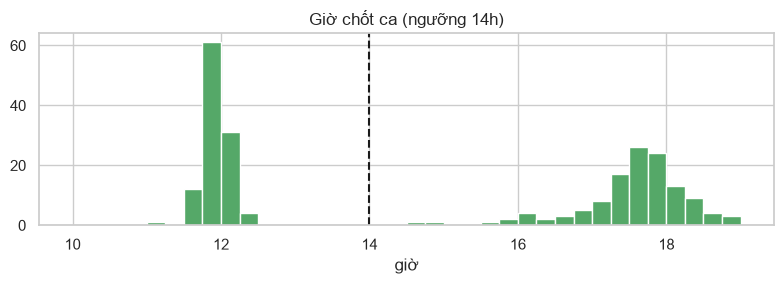

Theo giờ chốt,Chiều,Sáng
is_morning_shift (POS),,
False,125,0
True,2,109


,timestamp,is_morning_shift,shift,total_revenue
40,2026-01-09 17:37:47,True,Chiều,1468000
174,2026-03-29 18:34:04,True,Chiều,1240000


In [5]:
shifts = main[main.row_type == 'chốt ca'].copy().reset_index(drop=True)
shifts['close_hour'] = shifts.timestamp.dt.hour + shifts.timestamp.dt.minute / 60
shifts['shift'] = np.where(shifts.close_hour < 14, 'Sáng', 'Chiều')
shifts['flag_shift_label'] = shifts.is_morning_shift != (shifts['shift'] == 'Sáng')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(shifts.close_hour, bins=np.arange(10, 19.25, 0.25), color='C2')
ax.axvline(14, ls='--', c='k'); ax.set_title('Giờ chốt ca (ngưỡng 14h)'); ax.set_xlabel('giờ')
plt.tight_layout(); plt.show()

display(pd.crosstab(shifts.is_morning_shift, shifts['shift'], rownames=['is_morning_shift (POS)'], colnames=['Theo giờ chốt']))
display(shifts.loc[shifts.flag_shift_label, ['timestamp', 'is_morning_shift', 'shift', 'total_revenue']])

**Nhận xét:** giờ chốt ca tách thành 2 cụm rõ rệt (≈ 11h–12h và ≈ 17h–18h). Có **2 ca** POS ghi `is_morning_shift = True` nhưng chốt lúc 17h–18h. Từ đây dùng nhãn ca suy ra từ giờ chốt, và lưu cờ `flag_shift_label` để Vòng 4 báo lỗi dữ liệu.

### 3.3 Tiền két: độ tròn số và lỗi đơn vị

In [6]:
drawer_raw = shifts.actual_cash_in_drawer
print(f"Tiền két là bội số của 10.000 đ: {(drawer_raw % 10_000 == 0).mean():.1%} số ca")

shifts['flag_unit_typo'] = drawer_raw.between(1, 9_999)
shifts['drawer'] = np.where(shifts.flag_unit_typo, drawer_raw * 1000, drawer_raw)

typo = shifts.loc[shifts.flag_unit_typo, ['timestamp', 'shift', 'cash_amount', 'actual_cash_in_drawer', 'drawer']]
typo['phân vị sau khi sửa'] = typo.drawer.map(lambda v: (shifts.drawer < v).mean())
display(typo.style.format({'cash_amount': vnd, 'actual_cash_in_drawer': vnd, 'drawer': vnd, 'phân vị sau khi sửa': '{:.0%}'}))
print('Phân vị tiền két (sau khi sửa):', shifts.drawer.quantile([.05, .25, .5, .75, .95]).map(vnd).to_dict())

Tiền két là bội số của 10.000 đ: 97.5% số ca


,timestamp,shift,cash_amount,actual_cash_in_drawer,drawer,phân vị sau khi sửa
1,2025-12-20 17:54:52,Chiều,212.000 đ,860 đ,860.000 đ,22%
2,2025-12-21 11:45:24,Sáng,418.000 đ,490 đ,490.000 đ,2%
5,2025-12-22 17:38:18,Chiều,389.000 đ,1.270 đ,1.270.000 đ,58%
6,2025-12-23 11:42:08,Sáng,556.000 đ,480 đ,480.000 đ,1%
9,2025-12-24 18:28:09,Chiều,265.000 đ,1.230 đ,1.230.000 đ,54%


Phân vị tiền két (sau khi sửa): {0.05: '580.000 đ', 0.25: '890.000 đ', 0.5: '1.200.000 đ', 0.75: '1.540.000 đ', 0.95: '2.142.500 đ'}


**Nhận xét:** tiền két gần như luôn là bội số của 10.000 đ, tức là nhân viên đếm tròn nên sai số đếm khoảng ±10.000 đ (dùng làm `TOL`). Có **5 ca** ghi tiền két 480–1.270 đ: rõ ràng là gõ theo đơn vị nghìn. Sau khi nhân 1000, các giá trị rơi vào phân vị 1–58% của phân phối tiền két, tức là hợp lý. Bản v1 đã không sửa các ca này và gắn cờ "nghi thất thoát" cho chúng.

## 4. Đối soát hóa đơn với số chốt ca
Mỗi hóa đơn được gán vào lần chốt ca **ngay sau nó** (`merge_asof`, `direction='forward'`), rồi cộng lại để so với số máy ghi.

In [7]:
keys = shifts[['timestamp']].reset_index().rename(columns={'index': 'shift_id'})
bills = pd.merge_asof(det, keys, left_on='transaction_at', right_on='timestamp', direction='forward').drop(columns='timestamp')
print('Hóa đơn không gán được vào ca nào:', bills.shift_id.isna().sum())
bills['shift_id'] = bills.shift_id.astype(int)

agg = bills.groupby('shift_id').agg(
    bill_count=('total_revenue', 'size'), bill_revenue=('total_revenue', 'sum'),
    bill_cash=('cash_payment', 'sum'), bill_transfer=('transfer_payment', 'sum'),
    first_bill=('transaction_at', 'min'))
shifts = shifts.join(agg)

recon = pd.DataFrame({
    'Doanh thu': shifts.total_revenue - shifts.bill_revenue,
    'Tiền mặt': shifts.cash_amount - shifts.bill_cash,
    'Chuyển khoản': shifts.transfer_amount - shifts.bill_transfer})
display(pd.DataFrame({'Số ca lệch': (recon != 0).sum(), 'Lệch lớn nhất (đ)': recon.abs().max()}))

Hóa đơn không gán được vào ca nào: 0


,Số ca lệch,Lệch lớn nhất (đ)
Doanh thu,0,0
Tiền mặt,0,0
Chuyển khoản,0,0


**Nhận xét:** 100% ca khớp tuyệt đối giữa tổng hóa đơn và số chốt ca, kể cả ca chứa hóa đơn thiếu 8.000 đ ở trên. Điều này cho thấy POS **tính số chốt ca từ chính các hóa đơn**, nên phép đối soát này chỉ xác nhận phần mềm cộng đúng, **không phải kiểm tra độc lập**. Biến `Payment_Mismatch` của v1 vì thế luôn bằng 0 và không mang thông tin.

## 5. Dòng tiền két không giải thích được
Với mỗi lần chốt ca, lấy **lần đếm két hợp lệ gần nhất trước đó** (bỏ các dòng mở ca ghi 0, tức là không đếm).

In [8]:
counts = main[['timestamp', 'row_type', 'actual_cash_in_drawer']].copy()
counts['drawer'] = np.where(counts.actual_cash_in_drawer.between(1, 9_999), counts.actual_cash_in_drawer * 1000, counts.actual_cash_in_drawer)
counts = counts[~((counts.row_type == 'mở ca') & (counts.drawer == 0))]          # mở ca ghi 0 = không đếm
counts['prev_drawer'] = counts.drawer.shift()
counts['prev_count_at'] = counts.timestamp.shift()

shifts = shifts.merge(counts.loc[counts.row_type == 'chốt ca', ['timestamp', 'prev_drawer', 'prev_count_at']], on='timestamp', how='left')
shifts['expected_drawer'] = shifts.prev_drawer + shifts.cash_amount       # két nếu không ai rút/nạp tiền
shifts['cash_flow_gap'] = shifts.drawer - shifts.expected_drawer          # + : tiền vào không rõ nguồn, − : tiền ra không ghi nhận
shifts['overnight'] = shifts.timestamp.dt.date != shifts.prev_count_at.dt.date

shifts['flow_type'] = np.select(
    [shifts.cash_flow_gap > TOL, shifts.cash_flow_gap < -TOL],
    ['Tiền vào không rõ nguồn', 'Tiền ra không ghi nhận'], 'Khớp (±10k)')
display(pd.crosstab(shifts.flow_type, np.where(shifts.overnight, 'Qua đêm', 'Trong ngày'), margins=True, margins_name='Tổng'))
print('Phân vị cash_flow_gap:', shifts.cash_flow_gap.quantile([.05, .25, .5, .75, .95]).map(vnd).to_dict())

col_0,Qua đêm,Trong ngày,Tổng
flow_type,,,
Khớp (±10k),5,13,18
Tiền ra không ghi nhận,101,73,174
Tiền vào không rõ nguồn,22,22,44
Tổng,128,108,236


Phân vị cash_flow_gap: {0.05: '-1.445.750 đ', 0.25: '-731.500 đ', 0.5: '-250.000 đ', 0.75: '-9.500 đ', 0.95: '60.000 đ'}


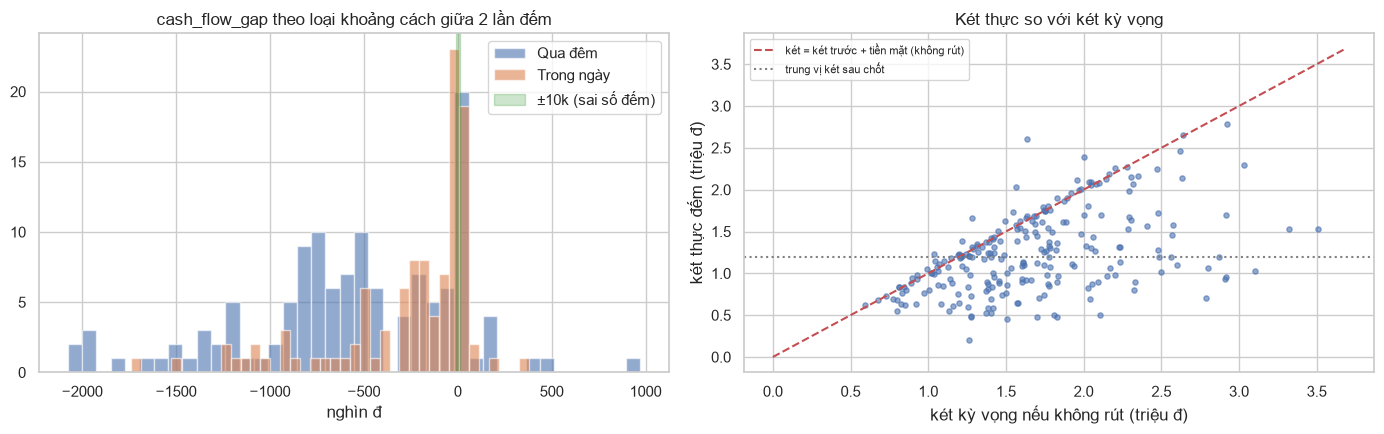

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lab, g in shifts.groupby(np.where(shifts.overnight, 'Qua đêm', 'Trong ngày')):
    ax[0].hist(g.cash_flow_gap / 1e3, bins=40, alpha=.6, label=lab)
ax[0].axvspan(-TOL / 1e3, TOL / 1e3, color='green', alpha=.2, label='±10k (sai số đếm)')
ax[0].set_title('cash_flow_gap theo loại khoảng cách giữa 2 lần đếm'); ax[0].set_xlabel('nghìn đ'); ax[0].legend()

ax[1].scatter(shifts.expected_drawer / 1e6, shifts.drawer / 1e6, s=14, alpha=.6)
lim = [0, shifts.expected_drawer.max() / 1e6 * 1.05]
ax[1].plot(lim, lim, 'r--', label='két = két trước + tiền mặt (không rút)')
ax[1].axhline(shifts.drawer.median() / 1e6, c='gray', ls=':', label='trung vị két sau chốt')
ax[1].set_xlabel('két kỳ vọng nếu không rút (triệu đ)'); ax[1].set_ylabel('két thực đếm (triệu đ)')
ax[1].set_title('Két thực so với két kỳ vọng'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / '01_cash_flow_gap.png', dpi=120); plt.show()

**Nhận xét:**
- **74%** số ca có *tiền ra không ghi nhận* (két thấp hơn két kỳ vọng hơn 10.000 đ), trung vị −250.000 đ. Ca qua đêm rút nhiều hơn ca trong ngày. Đây là hành vi bình thường: chủ quán rút tiền, chi tiêu mà không ghi lại. **Với dữ liệu hiện có không thể tách phần rút hợp lệ khỏi phần thất thoát.**
- **19%** số ca có *tiền vào không rõ nguồn* (két cao hơn kỳ vọng hơn 10.000 đ). Không ai rút tiền mà két lại tăng, nên đây là tín hiệu đáng xem: đơn chưa nhập POS, thu nợ, chủ quán nạp tiền lẻ, hoặc đếm sai.
- Biểu đồ phải: két thực luôn nằm **dưới** đường "không rút" và có xu hướng quay về khoảng 1,2 triệu đ, đúng kiểu *giữ lại tiền lẻ, rút phần dư*.

## 6. Vì sao `Cash_Diff` của bản v1 gây hiểu nhầm

In [10]:
v1_cash_diff = shifts.drawer - shifts.cash_amount
cmp = pd.DataFrame({
    'v1: Cash_Diff = két − tiền mặt ca': [f"{(v1_cash_diff > TOL).mean():.0%}", vnd(v1_cash_diff.median())],
    'v2: cash_flow_gap': [f"{(shifts.cash_flow_gap > TOL).mean():.0%}", vnd(shifts.cash_flow_gap.median())],
}, index=['Tỉ lệ ca "dư" (> +10k)', 'Trung vị'])
display(cmp)
print(f"Tương quan tiền mặt bán trong ca – tiền két: r = {shifts.cash_amount.corr(shifts.drawer):.2f}")
print(f"Trung vị tiền két / trung vị tiền mặt ca: {shifts.drawer.median() / shifts.cash_amount.median():.1f} lần")

,v1: Cash_Diff = két − tiền mặt ca,v2: cash_flow_gap
"Tỉ lệ ca ""dư"" (> +10k)",97%,19%
Trung vị,790.000 đ,-250.000 đ


Tương quan tiền mặt bán trong ca – tiền két: r = 0.13
Trung vị tiền két / trung vị tiền mặt ca: 2.9 lần


**Nhận xét:** tiền két lớn gần **3 lần** tiền mặt bán trong ca và gần như không tương quan với nó (r = 0,13). Chỉ số của v1 vì vậy cho ra **97% ca "dư két"**: con số này phản ánh tiền tồn két, không phải sai lệch. Với chỉ số mới, chỉ 19% ca có tiền vào không rõ nguồn.

## 7. Lưu kết quả

In [11]:
cols = ['timestamp', 'shift', 'close_hour', 'is_morning_shift', 'flag_shift_label', 'total_revenue', 'cash_amount', 'transfer_amount',
        'bill_count', 'actual_cash_in_drawer', 'flag_unit_typo', 'drawer', 'prev_drawer', 'prev_count_at', 'overnight',
        'expected_drawer', 'cash_flow_gap', 'flow_type']
shifts_out = shifts[cols].rename_axis('shift_id').reset_index()
shifts_out.to_csv(PROC / 'shifts_v2.csv', index=False)
bills.to_csv(PROC / 'bills_v2.csv', index=False)
print(f"Đã lưu {len(shifts_out)} ca -> {PROC / 'shifts_v2.csv'}")
print(f"Đã lưu {len(bills)} hóa đơn -> {PROC / 'bills_v2.csv'}")

Đã lưu 236 ca -> D:\Data Analysis\Data-Mining\Final-Project\data\processed_v2\shifts_v2.csv
Đã lưu 5412 hóa đơn -> D:\Data Analysis\Data-Mining\Final-Project\data\processed_v2\bills_v2.csv


## ✅ Tổng kết Vòng 1
| Kiểm tra | Kết quả |
|---|---|
| Hóa đơn | Sạch; 1 hóa đơn thiếu 8.000 đ |
| Dòng mở ca | 6 / 236 ca; 3 dòng ghi 0 = không đếm |
| Nhãn ca | 2 ca sai nhãn sáng/chiều |
| Tiền két | 5 ca gõ sai đơn vị → đã sửa ×1000 |
| Đối soát hóa đơn – chốt ca | Khớp 100% (POS tự cộng, không phải kiểm tra độc lập) |
| Dòng tiền két | 174 ca tiền ra không ghi nhận · 44 ca tiền vào không rõ nguồn · 18 ca khớp ±10k |

**Giới hạn quan trọng:** không có sổ ghi tiền rút và gần như không đếm két lúc mở ca, nên *tiền ra* không thể kết luận là thất thoát, còn *tiền vào* ở ca sáng có thể là tiền lẻ chủ quán bỏ thêm đầu ngày.